**Name**:

**Student ID**

## Shape Moments

In this section, we will utilize Shape Moments to detect and count pills in a photo. You are free to use any tool from the NumPy and OpenCV packages, except for the shape moment function, which you must implement manually.

In [ ]:
!pip install opencv-python numpy

## Mask Extraction
You are free to use any tools in this section. Your inputs should be the image path and any hyperparameters needed for mask creation.

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from typing import Any
def create_mask(image_path: str, **kwargs: Any) -> np.ndarray:

    ###### TODO ######

    ##################
    return fg_mask

## Shape Moments
Implement the shape moment function. You can use the following formula for your implementation. This is the closed-form formula for moment generation utilizing Green's theorem.

$$m_{pq} = \frac{1}{(p+q+1)(p+q+2)} \sum_{i=0}^{N-1} (x_i y_{i+1} - x_{i+1} y_i) \sum_{k=0}^{p} \sum_{l=0}^{q} \frac{\binom{p}{k} \binom{q}{l}}{\binom{p+q}{k+l}} x_i^{p-k} x_{i+1}^k y_i^{q-l} y_{i+1}^l$$

Note: You don't need to implement the formula, just use it for calculating the values needed for your task.

In [ ]:
import numpy as np
import math

def calculate_manual_moments(contour: np.ndarray) -> dict[str,float]:
    """
    Manually calculates moments for a contour using Green's Theorem.
    """
    ###### TODO ######

    ##################

    return moments

Use the moment function and the pill mask to detect the pills in the photo. Do not modify the function outside of the TODO section. Any conditions applied to the shapes must be directly related to their shape moments.


In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from typing import Any
# Pass the original 'img' into the function so we have something to draw the results on
def count_pills_with_moment(pill_mask, img, **kwargs: Any):

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

    clean_thresh = cv2.morphologyEx(pill_mask, cv2.MORPH_OPEN, kernel, iterations=1)

    _, clean_thresh = cv2.threshold(clean_thresh, 127, 255, cv2.THRESH_BINARY)

    contours, _ = cv2.findContours(clean_thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    valid_pill_count = 0

    # Draw your the selected contours on this image
    final_result_img = img.copy()


    for contour in contours:
        M = calculate_manual_moments(contour)
        perimeter = cv2.arcLength(contour, True)

        ###### TODO ######

        ##################

    print(f"\n--- Final Output (Total pills counted: {valid_pill_count}) ---")
    cv2_imshow(final_result_img)



Estimated Background Color (BGR): [178 178 232]


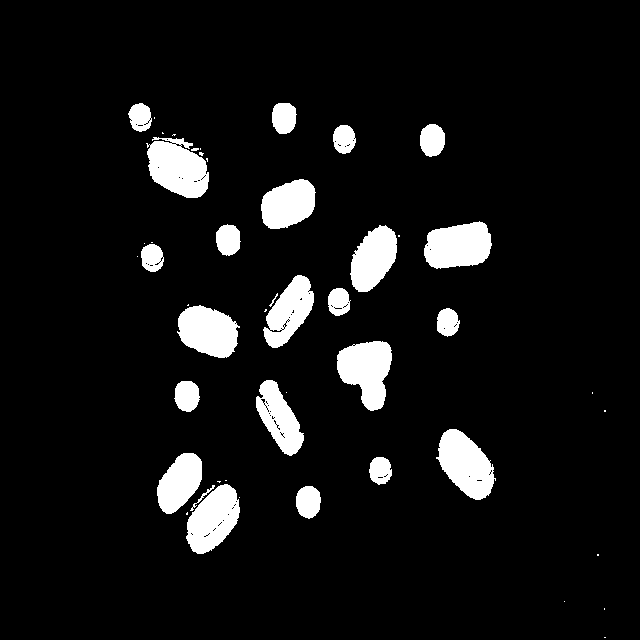

In [ ]:
# Load your original image and create the mask
original_img = cv2.imread('pills-pink.jpg')

pill_mask = create_mask('pills-pink.jpg', hue_tolerance=255, sat_tolerance=15,val_tolerance=15)

cv2_imshow(pill_mask)


--- Final Output (Total pills counted: 22) ---


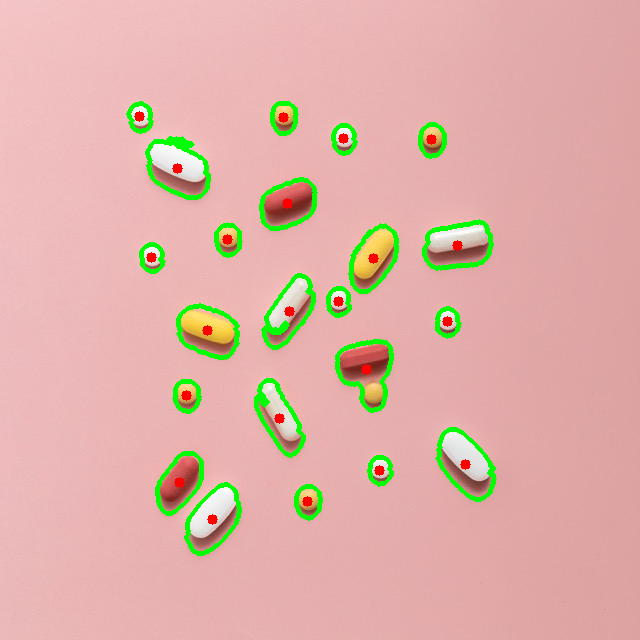

In [ ]:
# Detect all shapes of pills
kwargs = {}
count_pills_with_moment(pill_mask, original_img,kwargs)


--- Final Output (Total pills counted: 11) ---


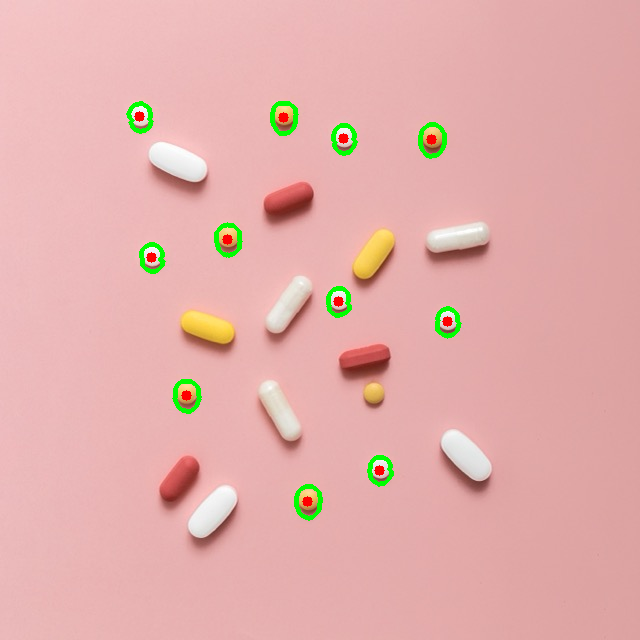

In [ ]:
#Detect the circular pills
kwargs = {}
count_pills_with_moment(pill_mask, original_img,kwargs)


--- Final Output (Total pills counted: 11) ---


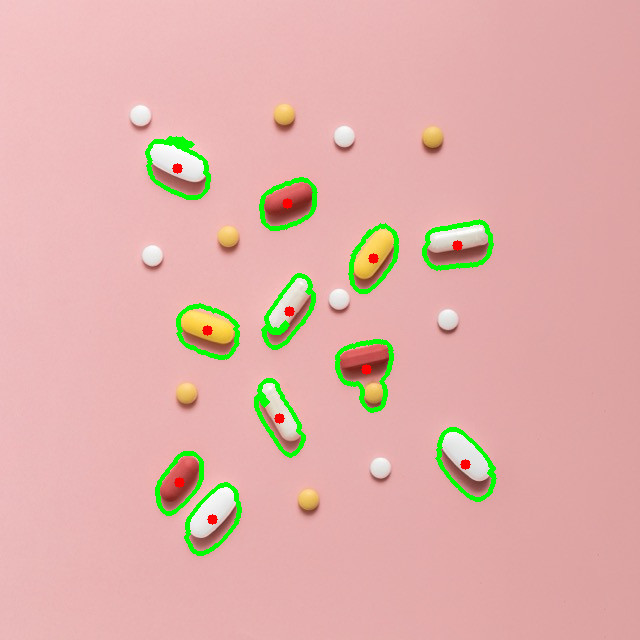

In [ ]:
#Detect the oval shaped pills
kwargs = {}
count_pills_with_moment(pill_mask, original_img,kwargs)


--- Final Output (Total pills counted: 4) ---


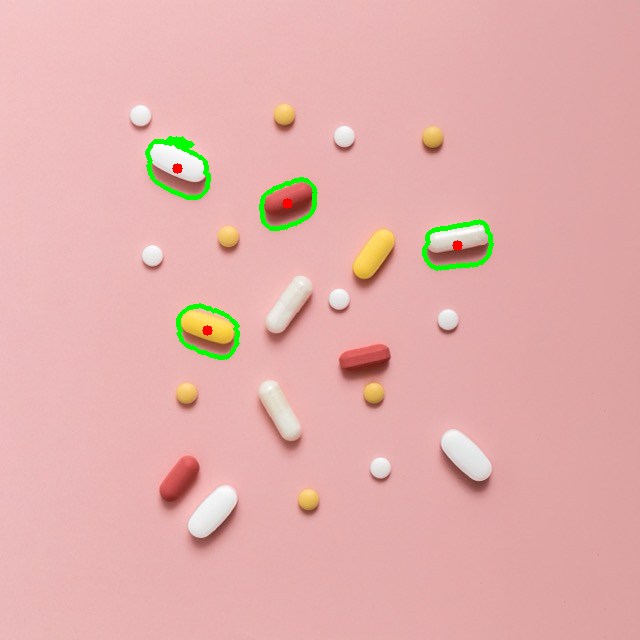

In [ ]:
#Detect slightly angled oval shaped pills (Use the sample output as your refrence)
kwargs = {}
count_pills_with_moment(pill_mask, original_img,kwargs)

# Template Matching

The objective of this section is to locate specific tablets within an image using a manual Template Matching algorithm. By taking a small reference crop (the template) of a single pill, we will mathematically compare it across the entire image to find matching regions.

## Image Enhancment

A simple Image_Enhancer function to seperate the white tablets

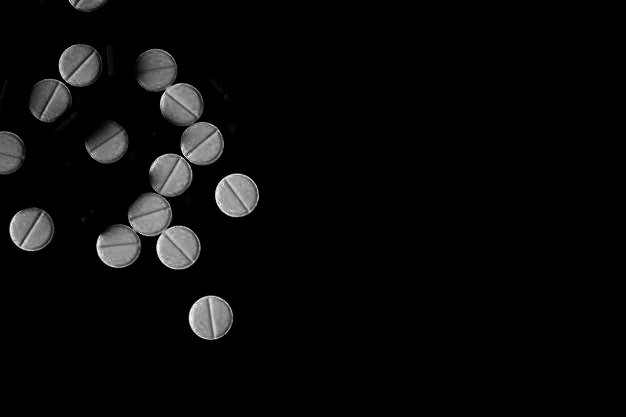

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
def Image_Enhancer(image_path:str) -> np.ndarray:
    image = cv2.imread(image_path)


    # 2. Run the feature extraction code
    ch2 = image[:, :, 2].astype(np.float64) # Red channel
    ch0 = image[:, :, 0].astype(np.float64) # Blue channel
    feature_extract = (ch0**6) * (ch2**2)

    max_val = np.max(feature_extract) + 1e-8
    enhanced_image = ((feature_extract / max_val) * 255).astype(np.uint8)
    
    cv2_imshow(enhanced_image)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

    return enhanced_image
enhanced_image = Image_Enhancer('pills-blue.jpg')

## Template Extraction

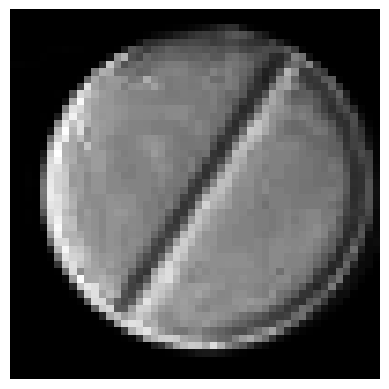

In [ ]:
import matplotlib.pyplot as plt
tmp_size=50
tr_y=205
tr_x=5
template=enhanced_image[tr_y:tr_y+tmp_size,tr_x:tr_x+tmp_size]
plt.imshow(template,cmap='gray')
plt.axis('off')
plt.show()


## Template Matcher

Write a template matching algorithm. You are strictly limited to using NumPy for this task. Instead of extracting only the single best match, use a manually defined threshold to include all acceptable results. Ensure that no tablet is detected more than once.

The output is an empty image with the bounding boxes drawn on it.

In [ ]:
import numpy as np

def template_matcher(img_array: np.ndarray, template: np.ndarray, threshold: float) -> np.ndarray:
    ###### TODO ######

    ##################
    print(f"Found {len(selected_points)} Tablets")
    return boxed

## Put Together

Found 14 Tablets


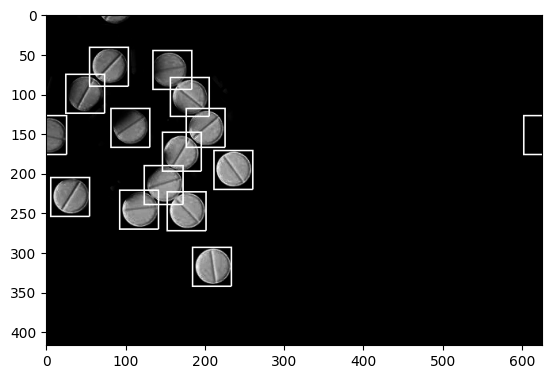

In [ ]:
box=template_matcher(enhanced_image,template, threshold= )

result=np.maximum(box,enhanced_image[:,:])
plt.imshow(result,cmap='gray')
plt.show()


# Conclusion
Test the shape moment algorithm on the blue pills image. Write a brief conclusion explaining which scenarios are best suited for each algorithm.